In [125]:
import pandas as pd
import os
import json
from docx import Document
import numpy as np
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)
import matplotlib.pyplot as plt
import seaborn as sns


In [10]:
Dir_github = r'X:\PROJECTS\ABC@UofSC\3-Experiments\NSF_valence\github'
repo = 'ABC_valence'
pipeline = 'getRatings_GPT'
Dir_working = os.path.join(Dir_github,repo,'scripts',pipeline)

result_folder = 'old_EshaSegmented'
model = 'gpt-4o-2024-08-06'
Dir_results = os.path.join(Dir_working,'results',result_folder,model)

List_files_all = os.listdir(Dir_results)
# Dir_instruct = os.path.join(Dir_working,'instructions')

In [43]:
# Dir_segments = os.path.join(Dir_github,'data','segmentation')
# df_story = pd.DataFrame({'story':[x for x in os.listdir(Dir_segments) if '_formatted.csv' in x ]})
# df_story['story'] = df_story['story'].str.split('_',expand=True)[1]
# for i,row in df_story.iterrows():
#     df_tmp = pd.read_csv(os.path.join(Dir_segments,f"segment_{row['story']}_formatted.csv"))
#     df_story.loc[i,'N_segments'] = df_tmp.shape[0]
# df_story.head()

Dir_transcript_seg = r'X:\PROJECTS\ABC@UofSC\3-Experiments\Affective_narrative\behavioral\segmentation_audacity\output\segmentation_transcript'
List_story = [x.split('_')[0] for x in os.listdir(Dir_transcript_seg) if '.docx' in x]
List_story

['AgedMother',
 'BiggestWastes',
 'BradfordBoar',
 'BulliesPronouns',
 'BulliesRepeatedNames',
 'Elvis',
 'EmpireState',
 'FairyTree',
 'FirstConcert',
 'HappyDay',
 'HowCouldYou',
 'Koko',
 'MetaphorsPronouns',
 'MetaphorsRepeatedNames',
 'ProfessionalDecline',
 'Roswell',
 'TaleofTwoCountries',
 'TigerandLion',
 'UserFriendly']

In [49]:

def preprocess_segments(story,shuffle):
    Dir_transcript_seg = r'X:\PROJECTS\ABC@UofSC\3-Experiments\Affective_narrative\behavioral\segmentation_audacity\output\segmentation_transcript'
    file = f'{story}_transcript_finished.docx'
    filepath = os.path.join(Dir_transcript_seg,file)
    doc = Document(os.path.join(Dir_transcript_seg,filepath))
    lines_story = []
    for paragraph in doc.paragraphs:
        line = paragraph.text.strip()
        if line:  # Ignore empty lines
            lines_story.append(line)
    

    for i,line in enumerate(lines_story):

        if line.startswith(' '):
            lines_story[i] = line[1:]
        lines_story[i] = lines_story[i].replace('\n','')
        # lines_story[i] = str(i+1)+' '+lines_story[i]
        while (lines_story[i][-1] in '",.…!?”“') | (lines_story[i].endswith(' ')) :
            lines_story[i] = lines_story[i][0:-1]

        # lines_story[i] = '#####'+lines_story[i]+'#####\n'
    N = len(lines_story)
    # lines_story = ' '.join(lines_story)
    return(lines_story,N)

In [77]:
df

,raw,idx,firstword,lastword,V,A
0,1 The Mother 0 2,1,The,Mother,0,2
1,2 Long mother 1 3,2,Long,mother,1,3
2,3 They food 1 2,3,They,food,1,2
3,4 and happy 2 2,4,and,happy,2,2
4,5 Shining leader -2 3,5,Shining,leader,-2,3
...,...,...,...,...,...,...
93,94 he gravely 0 2,94,he,gravely,0,2
94,"95 “Ah, saying 1 3",95,"“Ah,",saying,1,3
95,96 “with wisdom 1 3,96,“with,wisdom,1,3
96,97 That abolished 3 4,97,That,abolished,3,4


In [78]:
def check_alignment(df_input,df):
    flag = 1

    if df_input.shape[0]!=df.shape[0]:
        flag=-1

    df['input'] = df_input['input']
    for i,row in df.iterrows():
        flag1 = '0'
        flag2 = '0'
        input = row['input']
        word1 = row['firstword']
        word2 = row['lastword']
        if input.startswith(word1):
            flag1 = '1'
        if input.endswith(word2):
            flag2 = '1'
        df.loc[i,'flag'] = flag1+flag2
    return(df,flag)
    

In [138]:
dfs_score = []
for story in List_story:
        
    List_files = [x for x in List_files_all if '.json' in x and '_query' not in x and story in x]

    # check if have result outputs
    if len(List_files)==0:
        print(f"{story}: no results")

    # import raw input to check alignment
    lines_story,N_segs = preprocess_segments(story,0)
    df_input = pd.DataFrame({'input':lines_story})
    df_input['idx'] = df_input.index

    print(story,N_segs)

    for iter,file in enumerate(List_files):

        # import one iteration
        f = open(os.path.join(Dir_results,file))
        data = json.load(f)
        f.close()

        # List_texts = data['choices'][0]['message']['content'].replace('\n','').split('"""')
        List_texts = data['choices'][0]['message']['content'].replace('"""','').split('\n')
        df = pd.DataFrame({'raw':[x for x in List_texts if x!='']})
        # df[['idx','firstword','lastword','V','A']] = df['raw'].str.split(' ',expand=True)
        df[['idx','firstword']] = df['raw'].str.split(' ',2,expand=True)[[0,1]]
        df[['lastword','V','A']] = df['raw'].str.rsplit(' ',3,expand=True)[[1,2,3]]

        df_score,flag = check_alignment(df_input,df)
        if flag<0:
            print(f"{story}-iter{iter}:check alignment, incorrect N.")
            continue
        
        df_score.loc[df_score['flag']!='11',['V','A']] = np.nan
        df_score['story'] = story
        df_score['iteration'] = iter
        df_score['idx'] = df_score['idx'].astype(int)
        df_score['V'] = df_score['V'].astype(float)
        df_score['A'] = df_score['A'].astype(float)
        dfs_score.append(df_score)
dfs_score = pd.concat(dfs_score,ignore_index=True)
dfs_score

AgedMother 98
AgedMother-iter0:check alignment, incorrect N.
BiggestWastes 90
BradfordBoar 91
BulliesPronouns 80
BulliesRepeatedNames 80
Elvis 67
EmpireState 63
FairyTree 88
FirstConcert 57
HappyDay 55
HowCouldYou 74
Koko 44
MetaphorsPronouns 68
MetaphorsRepeatedNames 68
ProfessionalDecline 72
Roswell 58
TaleofTwoCountries 87
TigerandLion 100
UserFriendly 89


,raw,idx,firstword,lastword,V,A,input,flag,story,iteration
0,1 The Mother 0 2,1,The,Mother,0.0,2.0,The Aged Mother,11,AgedMother,1
1,2 Long mother 1 3,2,Long,mother,1.0,3.0,"Long, long ago there lived at the foot of the ...",11,AgedMother,1
2,3 They food 1 2,3,They,food,1.0,2.0,They owned a bit of land which supplied them w...,11,AgedMother,1
3,4 and happy 2 2,4,and,happy,2.0,2.0,"and they were humble, peaceful, and happy",11,AgedMother,1
4,5 Shining leader -2 4,5,Shining,leader,-2.0,4.0,Shining was governed by a despotic leader,11,AgedMother,1
...,...,...,...,...,...,...,...,...,...,...
14187,85 Once stylish: 1 3,85,Once,stylish:,1.0,3.0,"Once upon a time, a cane was stylish:",11,UserFriendly,9
14188,86 Today device -1 3,86,Today,device,-1.0,3.0,Today it is seen as a medical device,11,UserFriendly,9
14189,87 Why life -1 3,87,Why,life,-1.0,3.0,Why can’t we have walkers and canes for everyd...,11,UserFriendly,9
14190,88 to balance 1 3,88,to,balance,1.0,3.0,"to carry our packages, provide a way to sit wh...",11,UserFriendly,9


In [137]:
dfs_score.loc[dfs_score['flag']!='11'].groupby(['story']).count()

,raw,idx,firstword,lastword,V,A,input,flag,iteration
story,,,,,,,,,
AgedMother,65,65,65,65,0,0,65,65,65
BiggestWastes,73,73,73,73,0,0,73,73,73
BradfordBoar,107,107,107,107,0,0,107,107,107
BulliesPronouns,49,49,49,49,0,0,49,49,49
BulliesRepeatedNames,38,38,38,38,0,0,38,38,38
Elvis,65,65,65,65,0,0,65,65,65
EmpireState,70,70,70,70,0,0,70,70,70
FairyTree,103,103,103,103,0,0,103,103,103
FirstConcert,39,39,39,39,0,0,39,39,39


In [141]:
df_plot

,raw,idx,firstword,lastword,V,A,input,flag,story,iteration
13302,1 I me -3 6,1,I,me,-3.0,6.0,I wrote the book on user-friendly design. What...,11,UserFriendly,0
13303,2 More lives 3 5,2,More,lives,3.0,5.0,"More people than ever are living long, healthy...",11,UserFriendly,0
13304,3 According women 1 3,3,According,women,1.0,3.0,According to the U.S. Department of Health and...,11,UserFriendly,0
13305,4 More increases 1 3,4,More,increases,1.0,3.0,"More relevant, however, is that as people grow...",11,UserFriendly,0
13306,5 So women 1 3,5,So,women,1.0,3.0,"So for those who are now 65, the average life ...",11,UserFriendly,0
...,...,...,...,...,...,...,...,...,...,...
14187,85 Once stylish: 1 3,85,Once,stylish:,1.0,3.0,"Once upon a time, a cane was stylish:",11,UserFriendly,9
14188,86 Today device -1 3,86,Today,device,-1.0,3.0,Today it is seen as a medical device,11,UserFriendly,9
14189,87 Why life -1 3,87,Why,life,-1.0,3.0,Why can’t we have walkers and canes for everyd...,11,UserFriendly,9
14190,88 to balance 1 3,88,to,balance,1.0,3.0,"to carry our packages, provide a way to sit wh...",11,UserFriendly,9


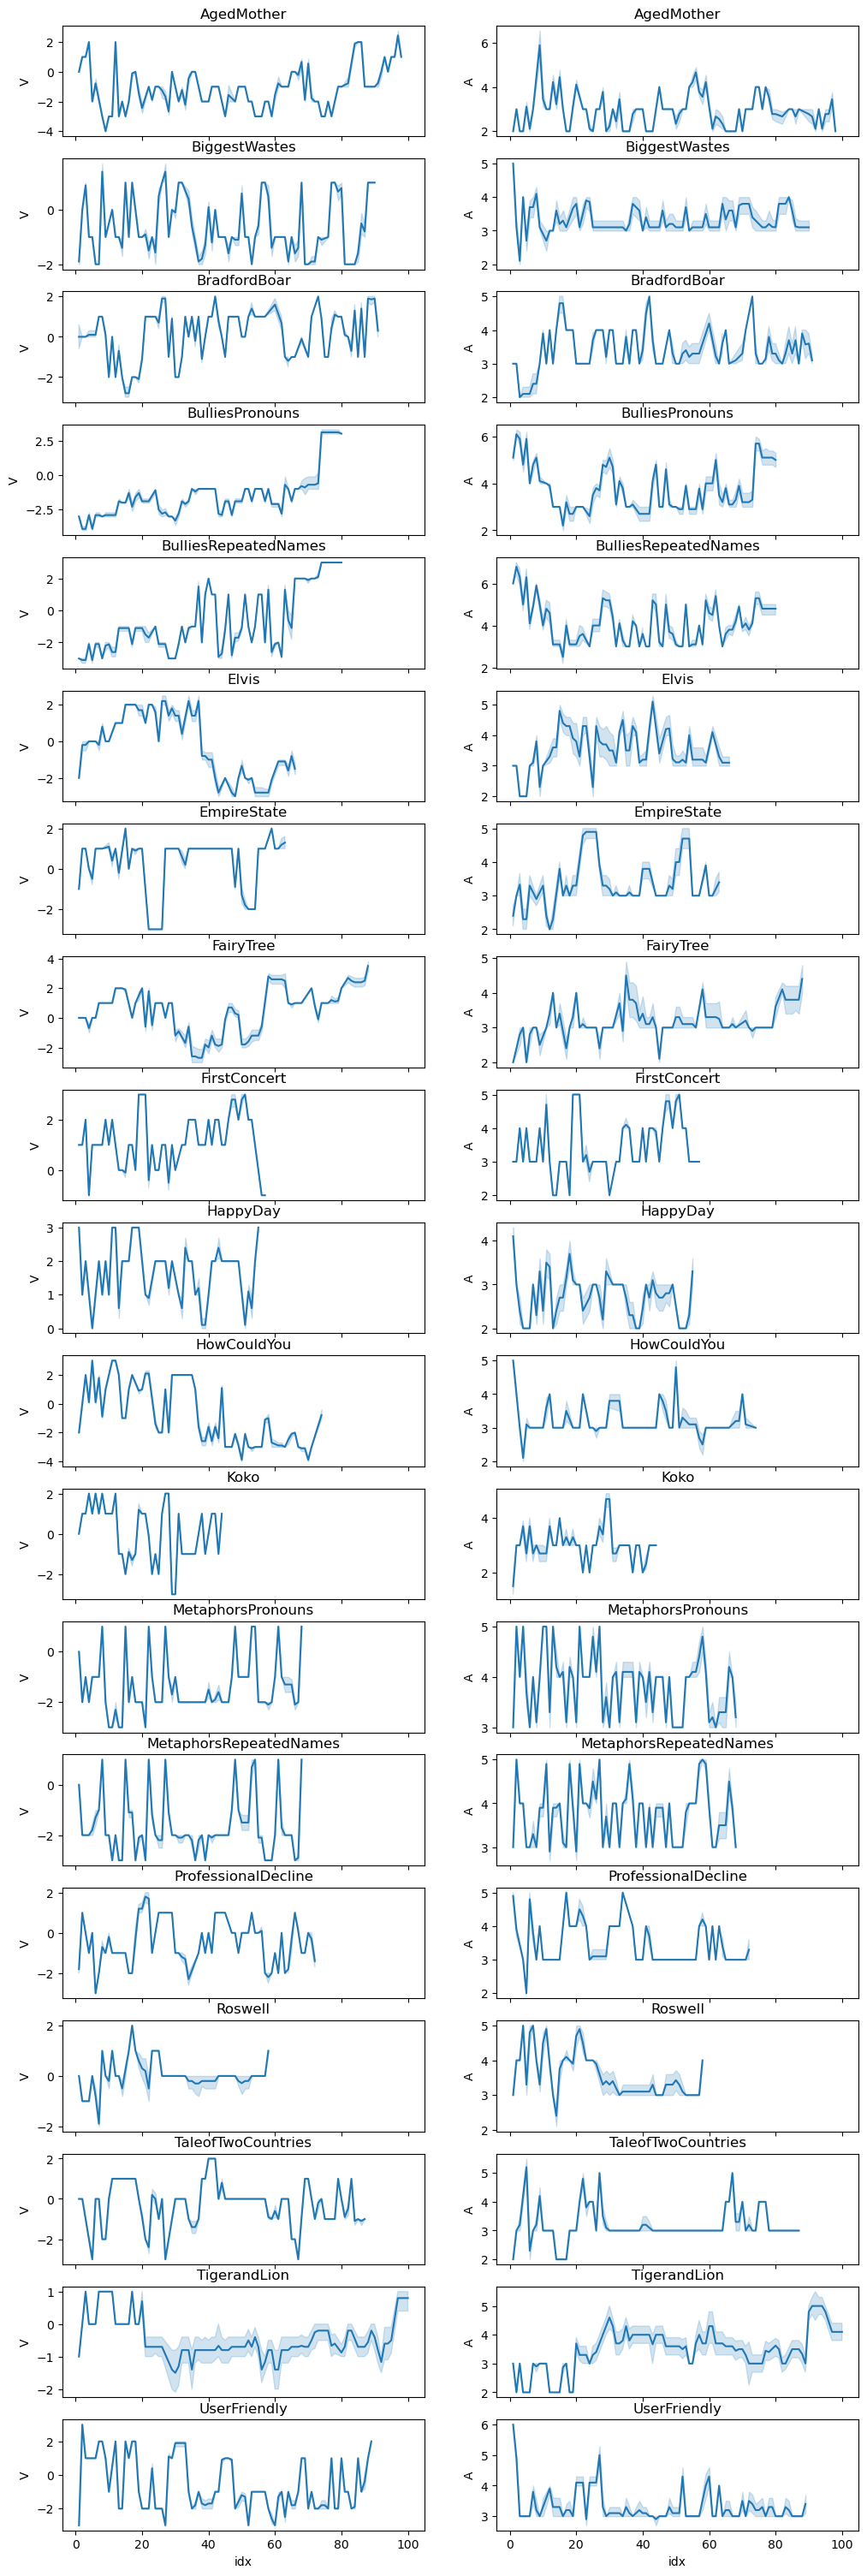

In [142]:
fig,axes = plt.subplots(nrows = len(List_story),ncols=2,figsize=(12,2*len(List_story)),sharex=True,sharey='col')
for i,story in enumerate(List_story):
    df_plot = dfs_score.loc[dfs_score['story']==story]
    sns.lineplot(data=df_plot,x='idx',y='V',ax=axes[i,0],errorbar='se').set_title(story)
    sns.lineplot(data=df_plot,x='idx',y='A',ax=axes[i,1],errorbar='se').set_title(story)


In [124]:
dfs_score_summary = dfs_score.groupby(['story','idx']).mean().reset_index()
dfs_score_summary['iteration'] = dfs_score.groupby(['story','idx']).count().reset_index()['iteration']
dfs_score_summary

,story,idx,V,A,iteration
0,AgedMother,1,0.0,2.000000,9
1,AgedMother,2,1.0,3.000000,9
2,AgedMother,3,1.0,2.000000,9
3,AgedMother,4,2.0,2.000000,9
4,AgedMother,5,-2.0,3.111111,9
...,...,...,...,...,...
1424,UserFriendly,85,1.0,3.000000,10
1425,UserFriendly,86,-1.0,3.000000,10
1426,UserFriendly,87,-0.4,3.000000,10
1427,UserFriendly,88,1.0,3.000000,10
